In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [31]:
out = "./results/estimator_quality/noise_0.0/opt_cfd/LeastSquare_10.0_1.0_10_1e-07.csv"

pd_ris = pd.read_csv(f"{out}")


In [32]:
labels = set(pd_ris['directions'].values)
num_directions = list(set(pd_ris['l'].values))
num_directions.sort()

In [33]:
pd_ris[pd_ris['directions'] == 'spherical' ].values

array([['spherical', 1, 2.559385875119137, 1.146479561695547,
        0.001015567779541, 1.0223793441673603e-05],
       ['spherical', 3, 1.3997250525062783, 0.2031672184301002,
        0.0010265827178955, 8.215448972428043e-06],
       ['spherical', 5, 0.9999999957070352, 1.503327866454645e-08,
        0.0010305166244506, 9.70223015948842e-06],
       ['spherical', 7, 0.6198602684048163, 0.0900373819940985,
        0.0010382413864135, 2.115783213485786e-05],
       ['spherical', 9, 0.2703315521228377, 0.123209914868908,
        0.0010854005813598, 2.221653096546216e-05],
       ['spherical', 10, 1.8616077048584098e-07, 1.9629561700760955e-07,
        0.0010443449020385, 1.0798572029914427e-05]], dtype=object)

In [34]:
num_directions

[1, 3, 5, 7, 9, 10]

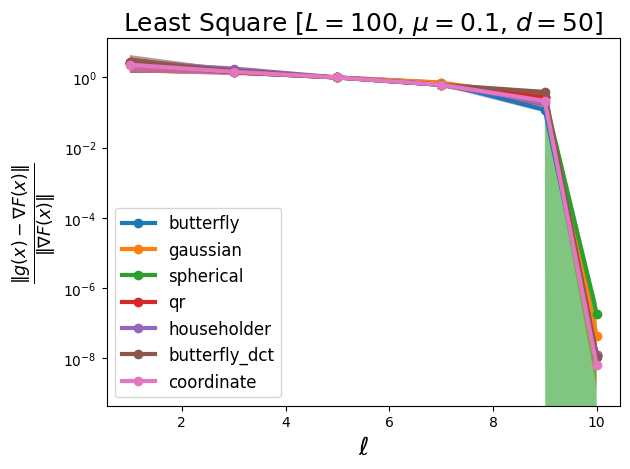

In [35]:

label_map = {
    'spherical' : 'unstructured',
    'householder' : 'structured',
}

fig, ax = plt.subplots()
for label in labels:
    mu_err  = pd_ris[pd_ris['directions'] == label ]['mu_err'].values
    std_err = pd_ris[pd_ris['directions'] == label ]['std_err'].values
    
    # if len(num_directions) > mu_err.shape[0]:
    #     mu_err = np.concatenate((mu_err, [mu_err[-1] for _ in range(len(num_directions) - mu_err.shape[0])]))
    #     std_err = np.concatenate((std_err, [std_err[-1] for _ in range(len(num_directions) - std_err.shape[0])]))
    
    ax.plot(num_directions, mu_err, 'o-', lw=3, label=label)
    ax.fill_between(num_directions, mu_err - std_err, mu_err + std_err, alpha=0.6 )
    
#ax.set_xscale('log')
#ax.axhline(1e-1, linestyle='--')

#ax.axvline(50, linestyle='--', color='red')
ax.set_yscale("log")
ax.set_ylabel("$ \\frac{\\| g(x) - \\nabla F(x) \\|}{\\| \\nabla F(x) \\|}$",fontsize=18)
ax.set_xlabel("$\\ell$", fontsize=18)
ax.legend(loc='lower left', fontsize=12)
ax.set_title("Least Square [$L = 100$, $\\mu = 0.1$, $d = 50$]", fontsize=18)
fig.tight_layout()
fig.savefig("./ls2_smt2.png", bbox_inches='tight')

In [45]:
out = "./results/estimator_quality/ffd/ls2_50_1e-07.csv"

pd_ris = pd.read_csv(f"{out}")

labels = set(pd_ris['directions'].values)
num_directions = list(set(pd_ris['l'].values))
num_directions.sort()


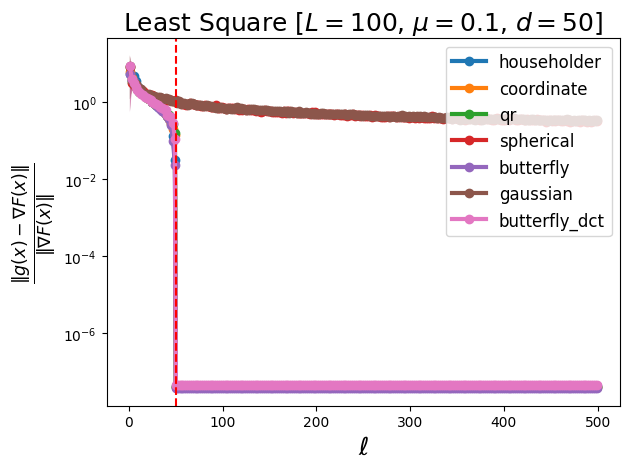

In [46]:

fig, ax = plt.subplots()
for label in labels:
    mu_err  = pd_ris[pd_ris['directions'] == label ]['mu_err'].values
    std_err = pd_ris[pd_ris['directions'] == label ]['std_err'].values
    
    if len(num_directions) > mu_err.shape[0]:
        mu_err = np.concatenate((mu_err, [mu_err[-1] for _ in range(len(num_directions) - mu_err.shape[0])]))
        std_err = np.concatenate((std_err, [std_err[-1] for _ in range(len(num_directions) - std_err.shape[0])]))
    
    ax.plot(num_directions, mu_err, 'o-', lw=3, label=label)
    ax.fill_between(num_directions, mu_err - std_err, mu_err + std_err, alpha=0.6 )
    
#ax.set_xscale('log')
#ax.axhline(1e-1, linestyle='--')

ax.axvline(50, linestyle='--', color='red')
ax.set_yscale("log")
ax.set_ylabel("$ \\frac{\\| g(x) - \\nabla F(x) \\|}{\\| \\nabla F(x) \\|}$",fontsize=18)
ax.set_xlabel("$\\ell$", fontsize=18)
ax.legend(loc='upper right', fontsize=12)
ax.set_title("Least Square [$L = 100$, $\\mu = 0.1$, $d = 50$]", fontsize=18)
fig.tight_layout()
fig.savefig("./ls2.png", bbox_inches='tight')

In [54]:

out = "/data/mrando/fdopt_results/estimator_quality/ffd/ARGTRIGLS_200_1e-05.csv"


pd_ris = pd.read_csv(f"{out}")




In [55]:
labels = set(pd_ris['directions'].values)
num_directions = list(set(pd_ris['l'].values))
num_directions.sort()

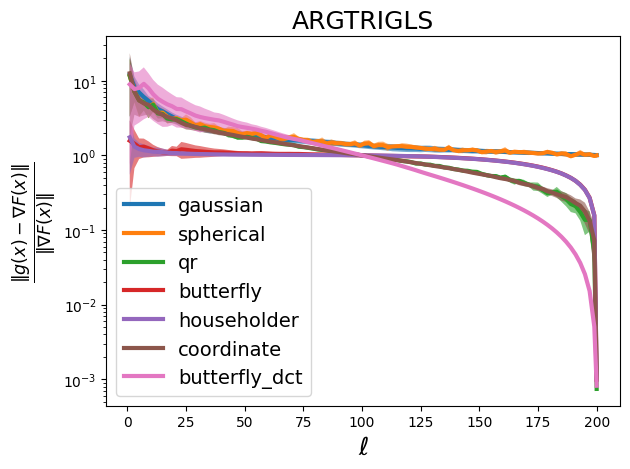

In [58]:


label_map = {
    'spherical' : 'unstructured',
    'householder' : 'structured',
}

fig, ax = plt.subplots()
for label in labels:
    mu_err  = pd_ris[pd_ris['directions'] == label ]['mu_err'].values
    std_err = pd_ris[pd_ris['directions'] == label ]['std_err'].values
    ax.plot(num_directions, mu_err, '-', lw=3, label=label)
    ax.fill_between(num_directions, mu_err - std_err, mu_err + std_err, alpha=0.6 )
    
#ax.set_xscale('log')
#ax.axhline(1e-1, linestyle='--')
ax.set_yscale("log")
ax.set_ylabel("$ \\frac{\\| g(x) - \\nabla F(x) \\|}{\\| \\nabla F(x) \\|}$",fontsize=18)
ax.set_xlabel("$\\ell$", fontsize=18)
ax.legend(fontsize=14)
ax.set_title("ARGTRIGLS", fontsize=18)
fig.tight_layout()
fig.savefig("./ARGTRIGLS.png", bbox_inches='tight')

## Birthday Paradox

In [98]:
from fdopt.direction_generators import SphericalDirections, Householder

In [220]:
import torch
d = 100
l = 70
sph_gen = SphericalDirections(d = d, l = l, dtype=torch.float64)
h_gen = Householder(d = d, l = l, dtype=torch.float64)

In [221]:
H = h_gen().T
S = sph_gen().T


[   0    0    0    0    0    0    0 2415    0    0    0    0    0    0
    0]


(-0.0015997191836376132, 0.3153935645878393, -0.31032670848017657)

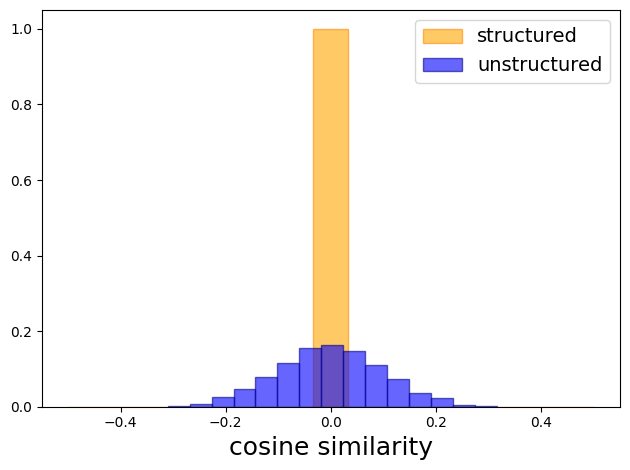

In [222]:
import numpy as np
import matplotlib.pyplot as plt


# Compute dot products (cosine similarity) between all pairs
dot_products = (S.T @ S).numpy() #np.dot(vectors.T, vectors)
dot_products[ abs(dot_products) < 1e-9] = 0.0
np.fill_diagonal(dot_products, 0)  # Remove self-dot products (which are always 1)

orth_dot_products = (H.T @ H).numpy()# np.dot(orth.T, orth)
orth_dot_products[abs(orth_dot_products) < 1e-9] = 0.0
np.fill_diagonal(orth_dot_products, 0)  # Remove self-dot products (which are always 1)



# Extract upper triangle (excluding diagonal) to avoid duplicate pairs
dot_product_values = dot_products[np.triu_indices(l, k=1)]
orth_dot_product_values = orth_dot_products[np.triu_indices(l, k=1)]


counts, bin_edges = np.histogram(dot_product_values, bins=15)
normalized_counts = counts / np.sum(counts)

orthcounts, orthbin_edges = np.histogram(orth_dot_product_values, bins=15)
orthnormalized_counts = orthcounts / np.sum(orthcounts)

print(orthcounts)


# Compute bin centers for better visualization
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
orth_bin_centers = (orthbin_edges[:-1] + orthbin_edges[1:]) / 2


# Plot histogram of dot products
fig, ax = plt.subplots() #plt.figure(figsize=(8, 5))



ax.bar(orth_bin_centers, orthnormalized_counts, width=(orthbin_edges[1] - orthbin_edges[0]), color='orange', alpha=0.6, edgecolor='darkorange', label='structured')
ax.bar(bin_centers, normalized_counts, width=(bin_edges[1] - bin_edges[0]), color='b', alpha=0.6, edgecolor='darkblue', label='unstructured')

#ax.hist(dot_product_values.flatten(), density=False, bins=bin_centers, alpha=0.7, color='b', edgecolor='darkblue', label='unstructured')
#ax.hist(orth_dot_product_values.flatten(), density=False,  alpha=0.7, color='orange', edgecolor='darkorange', label='structured')
ax.set_xlabel("cosine similarity", fontsize=18)
ax.legend(fontsize=14)

fig.tight_layout()
#ax.set_yscale("log")

# Print some statistics
mean_dot = np.mean(dot_product_values)
max_dot = np.max(dot_product_values)
min_dot = np.min(dot_product_values)


#fig.savefig("./cos_sim.png", bbox_inches='tight')
mean_dot, max_dot, min_dot


In [ ]:
num_fully_orthogonal

Done for 500
Done for 1000
Done for 1500
Done for 2000
Done for 5000


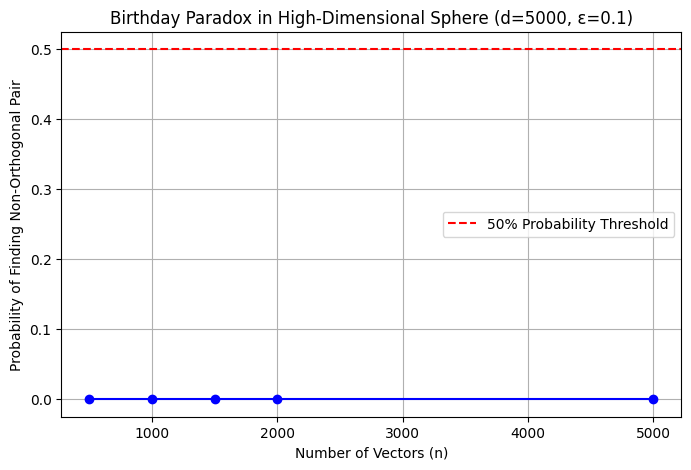

In [244]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
d = 5000  # Dimension
n_values = [500, 1000, 1500, 2000, 5000]#, 7000, 9000, 9500, 9600, 9800, 9900, 9990, 10000]
epsilon = 0.1  # Threshold for "non-orthogonality"
num_trials = 10  # Number of trials for probability estimation

# Function to check if any pair exceeds threshold
def has_non_orthogonal_pair(n, d, epsilon):
    vectors = np.random.randn(n, d)
    vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)  # Normalize to unit vectors
    dot_products = np.dot(vectors, vectors.T)  # Compute all pairwise dot products
    np.fill_diagonal(dot_products, 0)  # Ignore self-dot products
    return np.any(np.abs(dot_products) > epsilon)  # Check if any pair exceeds threshold

# Estimate probability for different n values
probabilities = []
for n in n_values:
    count = sum(has_non_orthogonal_pair(n, d, epsilon) for _ in range(num_trials))
    probabilities.append(count / num_trials)
    print(f"Done for {n}")

# Plot results
plt.figure(figsize=(8, 5))
plt.plot(n_values, probabilities, marker='o', linestyle='-', color='b')
plt.axhline(0.5, color='r', linestyle='--', label='50% Probability Threshold')
plt.xlabel("Number of Vectors (n)")
plt.ylabel("Probability of Finding Non-Orthogonal Pair")
plt.title(f"Birthday Paradox in High-Dimensional Sphere (d={d}, ε={epsilon})")
plt.legend()
plt.grid(True)
plt.show()


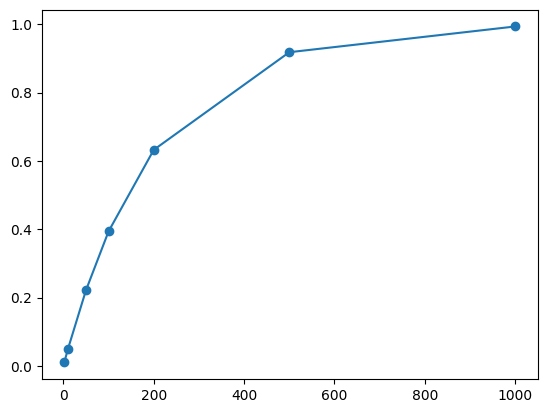

In [254]:
def orthog_prob(d, eps=0.1):
    return  1- np.exp(-d * (eps**2)/2)

dimensions = [2, 10, 50, 100, 200, 500, 1000]

y = [orthog_prob(d) for d in dimensions]

fig, ax = plt.subplots()

ax.plot(dimensions, y, 'o-')

